In [99]:
SetDirectory["/home/tyywork/DM/2Dphi4/mathematica"];
Get["/home/tyywork/DM/mathematica/academic.m"];
Needs["MaTeX`"];

datDir = "/home/tyywork/DM/2Dphi4/results/dm_vs_hmc_L128/dat_cache";
figDir = "/home/tyywork/DM/2Dphi4/results/dm_vs_hmc_L128/figures";
If[!DirectoryQ[figDir], CreateDirectory[figDir]];

kappas    = {"0.26", "0.2705", "0.28"};
phaseStr  = <|"0.26" -> "sym", "0.2705" -> "crit", "0.28" -> "broken"|>;
massFracs = {0.2, 0.5, 0.9, 0.98};
nG        = 100;

densCF     = ColorData["ThermometerColors"];
bandColors = Prepend[
  Directive[densCF[#], Opacity[0.88]] & /@ {0.30, 0.50, 0.72, 0.92},
  None];

massLevels[Z_, fracs_] := With[{f = Reverse@Sort@Flatten[Z]},
  With[{c = Accumulate[f]/Total[f]},
    Sort[f[[Min[Count[c, x_ /; x < #] + 1, Length[f]]]] & /@ fracs]]];

In [112]:
(* ===== makePanel: load → KDE-grid → plot, all in one =====
   Parameters preserved: bandwidth 0.1, mMax×1.2, yR ±10·range, PlotRange -> All.
   ShowLegend=True draws an in-plot HMC/DM legend centered in the panel. *)
Options[makePanel] = {"FontSize" -> 18, "ImageSize" -> 420,
                      "ShowLegend" -> False};
makePanel[kStr_String, OptionsPattern[]] := Module[
  {hmcPts, dmPts, mMax, svLo, svHi, xR, yR, gridZ,
   Zh, Zd, hmcLvls, dmLvls, fs, fracStr, annot, legendRow, legend, epi},
  fs = OptionValue["FontSize"];

  hmcPts = Import[FileNameJoin[{datDir, "mS_pts_k" <> kStr <> "_HMC.dat"}],
                  "Table", "HeaderLines" -> 1];
  dmPts  = Import[FileNameJoin[{datDir, "mS_pts_k" <> kStr <> "_DM.dat"}],
                  "Table", "HeaderLines" -> 1];

  mMax = 1.2 Quantile[Abs[Join[hmcPts, dmPts][[All, 1]]], 0.995];
  {svLo, svHi} = Quantile[Join[hmcPts, dmPts][[All, 2]], {0.005, 0.995}];
  xR = {-mMax, mMax};
  yR = {svLo, svHi} + 10 (svHi - svLo) {-1, 1};

  gridZ[pts_] := Table[PDF[SmoothKernelDistribution[pts, 0.1], {x, y}],
    {x, Subdivide[xR[[1]], xR[[2]], nG - 1]},
    {y, Subdivide[yR[[1]], yR[[2]], nG - 1]}];
  Zh = gridZ[hmcPts]; Zd = gridZ[dmPts];
  hmcLvls = massLevels[Zh, massFracs];
  dmLvls  = massLevels[Zd, massFracs];

  fracStr = "(" <> StringRiffle[ToString /@ Round[100 massFracs], "/"] <> "\\%)";

  annot = Inset[
    MaTeX["\\kappa=" <> kStr <> "\\;(\\text{" <> phaseStr[kStr] <> "})",
          FontSize -> fs + 2],
    Scaled[{0.5, 0.95}], {Center, Top},
    Background -> Directive[White, Opacity[0.85]]];

  legendRow[swatch_, label_] := Row[{
    Graphics[swatch, ImageSize -> {32, 14}], Spacer[6],
    MaTeX["\\text{" <> label <> "}\\;" <> fracStr, FontSize -> fs]}];

  legend = Inset[
    Framed[
      Column[{
        legendRow[{densCF[0.72], Opacity[0.88], Rectangle[{0, 0}, {1.4, 0.5}]}, "HMC"],
        legendRow[{Black, AbsoluteThickness[1.6], Dashed, Line[{{0, 0.5}, {1.4, 0.5}}]}, "DM"]},
        Spacings -> 0.4, Alignment -> Left],
      Background -> Directive[White, Opacity[0.9]],
      FrameStyle -> Directive[Gray, AbsoluteThickness[0.6]],
      RoundingRadius -> 4, FrameMargins -> 6],
    Scaled[{0.5, 0.5}]];

  epi = If[OptionValue["ShowLegend"], {annot, legend}, {annot}];

  Show[
    ListContourPlot[Transpose[Zh], DataRange -> {xR, yR},
      Contours -> hmcLvls, ContourShading -> bandColors,
      ContourLines -> False, InterpolationOrder -> 1],
    ListContourPlot[Transpose[Zd], DataRange -> {xR, yR},
      Contours -> dmLvls, ContourShading -> None,
      ContourStyle -> Directive[Black, Dashed, AbsoluteThickness[1.2]],
      InterpolationOrder -> 1],
    PlotRange -> All, PlotRangePadding -> None,
    AspectRatio -> 1, Frame -> True,
    FrameLabel -> {
      MaTeX["m=\\tfrac{1}{V}\\sum_{x}\\phi_{x}", FontSize -> fs + 4],
      MaTeX["S/V", FontSize -> fs + 4]},
    FrameTicksStyle -> Directive[FontSize -> fs],
    Epilog -> epi,
    ImageSize -> OptionValue["ImageSize"]]
];

-Graphics-   -Graphics-   -Graphics-
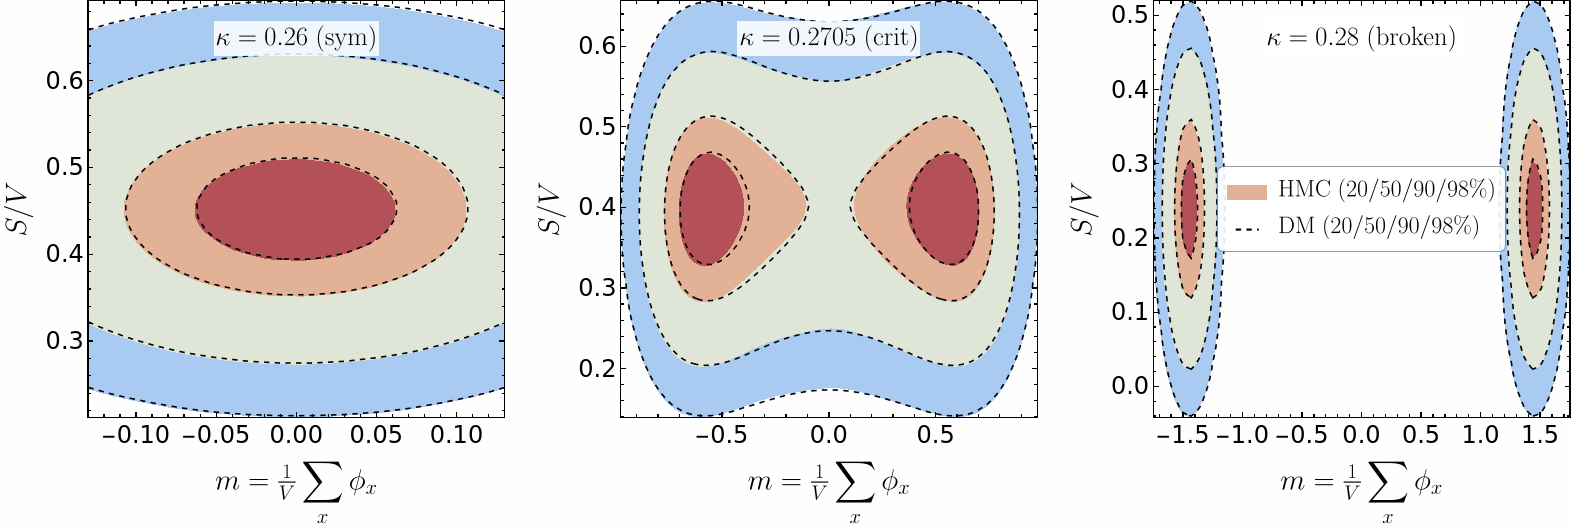

In [ ]:
(* ===== 1×3 composite — legend only on the third (κ=0.28) panel ===== *)
panels = MapIndexed[
  makePanel[#1, "FontSize" -> 18, "ImageSize" -> 380,
                "ShowLegend" -> (First[#2] == Length[kappas])] &,
  kappas];
composite = Grid[{panels},
  Spacings -> {1.5, 0}, Frame -> None, Alignment -> {Center, Center}];
composite

In [ ]:
(* ===== Export composite ===== *)
fn = FileNameJoin[{figDir, "test_mS_joint_3panels.pdf"}];
Export[fn, composite];
{fn, N@FileByteCount[fn]/1024., " KB"}

{/home/tyywork/DM/2Dphi4/results/dm_vs_hmc_L128/figures/test_mS_joint_3panels.pdf, 
 
>   3945.45,  KB}